# Bitly Data from 1.USA.gov

- Vào năm 2011, dịch vụ rút gọn URL Bitly đã hợp tác với trang web của chính phủ Hoa Kỳ – USA.gov để cung cấp một nguồn dữ liệu ẩn danh được thu thập từ người dùng khi họ rút gọn các liên kết có đuôi .gov hoặc .mil.

- Trong năm đó, luồng dữ liệu trực tiếp (live feed) cùng với các bản chụp dữ liệu theo giờ (hourly snapshots) đều được công bố công khai dưới dạng tệp văn bản có thể tải xuống.

- Hiện tại (tính đến năm 2022), dịch vụ này đã ngừng hoạt động, nhưng một trong các tệp dữ liệu gốc đã được lưu giữ lại để sử dụng làm ví dụ trong cuốn sách này.

In [1]:

from numpy.random import randn
import numpy as np
np.random.seed(123)
import os
import matplotlib.pyplot as plt
import pandas as pd
plt.rc("figure", figsize=(10, 6))
np.set_printoptions(precision=4)
pd.options.display.max_columns = 20
pd.options.display.max_rows = 20
pd.options.display.max_colwidth = 80

In [6]:
path = "datasets/bitly_usagov/example.txt"

- Trong trường hợp các bản chụp dữ liệu theo giờ (hourly snapshots), mỗi dòng trong mỗi tệp chứa một dạng dữ liệu web phổ biến được gọi là JSON (JavaScript Object Notation).

- Ví dụ, nếu chúng ta đọc dòng đầu tiên của một tệp, ta có thể thấy một cấu trúc dữ liệu tương tự như sau:

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
with open(path) as f:
    print(f.readline())

FileNotFoundError: [Errno 2] No such file or directory: 'datasets/bitly_usagov/example.txt'

- Python có sẵn cả thư viện tích hợp (built-in) và thư viện của bên thứ ba (third-party) để chuyển đổi một chuỗi JSON (JSON string) thành từ điển (dictionary) trong Python.

- Trong ví dụ này, ta sẽ sử dụng mô-đun json có sẵn trong Python, cùng với hàm loads(), để đọc và chuyển đổi từng dòng trong tệp dữ liệu mẫu mà chúng ta đã tải về.

In [ ]:
import json
with open(path) as f:
    records = [json.loads(line) for line in f]

Kết quả

In [ ]:
records[0] # xem dòng đầu tiên trong tệp dữ liệu

{'a': 'Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/535.11 (KHTML, like Gecko) Chrome/17.0.963.78 Safari/535.11',
 'c': 'US',
 'nk': 1,
 'tz': 'America/New_York',
 'gr': 'MA',
 'g': 'A6qOVH',
 'h': 'wfLQtf',
 'l': 'orofrog',
 'al': 'en-US,en;q=0.8',
 'hh': '1.usa.gov',
 'r': 'http://www.facebook.com/l/7AQEFzjSi/1.usa.gov/wfLQtf',
 'u': 'http://www.ncbi.nlm.nih.gov/pubmed/22415991',
 't': 1331923247,
 'hc': 1331822918,
 'cy': 'Danvers',
 'll': [42.576698, -70.954903]}

## Counting Time Zones in Pure Python

- Giả sử chúng ta muốn tìm ra các múi giờ (time zones) xuất hiện thường xuyên nhất trong tập dữ liệu — tức là trường tz (time zone) trong mỗi bản ghi.

- Có nhiều cách để thực hiện việc này, nhưng đầu tiên, ta sẽ trích xuất danh sách các múi giờ từ dữ liệu bằng list comprehension trong Python.

In [ ]:
time_zones = [rec["tz"] for rec in records]

KeyError: 'tz'

-> Lý do lỗi là vì không phải tất cả các bản ghi đều có trường múi giờ. Chúng ta có thể xử lý vấn đề này bằng cách thêm lệnh check if "tz" trong rec vào cuối phần đọc hiểu danh sách:

In [ ]:
time_zones = [rec["tz"] for rec in records if "tz" in rec]
time_zones[:10]

['America/New_York',
 'America/Denver',
 'America/New_York',
 'America/Sao_Paulo',
 'America/New_York',
 'America/New_York',
 'Europe/Warsaw',
 '',
 '',
 '']

- Khi xem qua 10 múi giờ đầu tiên, ta thấy rằng một số giá trị bị thiếu hoặc không xác định (ví dụ: chuỗi rỗng "").
Ta hoàn toàn có thể lọc bỏ các giá trị này, nhưng tạm thời giữ nguyên để quan sát toàn bộ dữ liệu.

- Tiếp theo, để thống kê số lần xuất hiện của từng múi giờ, ta sẽ trình bày hai cách tiếp cận:
    - Cách thứ nhất (khó hơn) — chỉ sử dụng thư viện chuẩn của Python (Python Standard Library).
    - Cách thứ hai (đơn giản hơn) — sử dụng thư viện pandas.

In [ ]:
def get_counts(sequence):
    counts = {}
    for x in sequence:
        if x in counts:
            counts[x] += 1
        else:
            counts[x] = 1
    return counts

Sử dụng các công cụ nâng cao hơn trong thư viện chuẩn Python, bạn có thể viết lại nội dung tương tự một cách ngắn gọn hơn:

In [ ]:
from collections import defaultdict

def get_counts2(sequence):
    counts = defaultdict(int) # values will initialize to 0
    for x in sequence:
        counts[x] += 1
    return counts

- Gọi hàm

In [ ]:
counts = get_counts(time_zones)
counts["America/New_York"]
len(time_zones)

3440

- Nếu chúng ta muốn biết 10 múi giờ hàng đầu và số lượng của chúng, chúng ta có thể tạo một danh sách các bộ dữ liệu theo
(số lượng, múi giờ) và sắp xếp nó:

In [ ]:
def top_counts(count_dict, n=10):
    value_key_pairs = [(count, tz) for tz, count in count_dict.items()]
    value_key_pairs.sort()
    return value_key_pairs[-n:]

- Kết quả

In [ ]:
top_counts(counts)

[(33, 'America/Sao_Paulo'),
 (35, 'Europe/Madrid'),
 (36, 'Pacific/Honolulu'),
 (37, 'Asia/Tokyo'),
 (74, 'Europe/London'),
 (191, 'America/Denver'),
 (382, 'America/Los_Angeles'),
 (400, 'America/Chicago'),
 (521, ''),
 (1251, 'America/New_York')]

- Nếu bạn tìm kiếm trong thư viện chuẩn Python, bạn có thể tìm thấy lớp collections.Counter
giúp nhiệm vụ này trở nên đơn giản hơn:

In [ ]:
from collections import Counter
counts = Counter(time_zones)
counts.most_common(10)

[('America/New_York', 1251),
 ('', 521),
 ('America/Chicago', 400),
 ('America/Los_Angeles', 382),
 ('America/Denver', 191),
 ('Europe/London', 74),
 ('Asia/Tokyo', 37),
 ('Pacific/Honolulu', 36),
 ('Europe/Madrid', 35),
 ('America/Sao_Paulo', 33)]

## Counting Time Zones with pandas

- Bạn có thể tạo DataFrame từ tập hợp bản ghi gốc bằng cách truyền danh sách
bản ghi cho pandas.DataFrame:

In [ ]:
frame = pd.DataFrame(records)

- Bạn có thể xem được những thông tin cơ bản của tập dataframe chẳng hạng như cột, tên, kiểu dữ liệu của cột, giá trị null

In [ ]:
frame.info()
frame["tz"].head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3560 entries, 0 to 3559
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   a            3440 non-null   object 
 1   c            2919 non-null   object 
 2   nk           3440 non-null   float64
 3   tz           3440 non-null   object 
 4   gr           2919 non-null   object 
 5   g            3440 non-null   object 
 6   h            3440 non-null   object 
 7   l            3440 non-null   object 
 8   al           3094 non-null   object 
 9   hh           3440 non-null   object 
 10  r            3440 non-null   object 
 11  u            3440 non-null   object 
 12  t            3440 non-null   float64
 13  hc           3440 non-null   float64
 14  cy           2919 non-null   object 
 15  ll           2919 non-null   object 
 16  _heartbeat_  120 non-null    float64
 17  kw           93 non-null     object 
dtypes: float64(4), object(14)
memory usage: 500.8+ K

0     America/New_York
1       America/Denver
2     America/New_York
3    America/Sao_Paulo
4     America/New_York
Name: tz, dtype: object

- Đầu ra được hiển thị cho khung là chế độ xem tóm tắt, được hiển thị cho các đối tượng DataFrame lớn. Sau đó, chúng ta có thể sử dụng phương thức value_counts cho Series:

In [ ]:
tz_counts = frame["tz"].value_counts()
tz_counts.head()

tz
America/New_York       1251
                        521
America/Chicago         400
America/Los_Angeles     382
America/Denver          191
Name: count, dtype: int64

- Chúng ta có thể trực quan hóa dữ liệu này bằng thư viện matplotlib.
- Để biểu đồ trông trực quan và rõ ràng hơn, ta cần xử lý trước (data cleaning) những giá trị múi giờ bị thiếu hoặc không xác định trong dữ liệu.

- Cụ thể, ta sẽ thay thế các giá trị bị thiếu (NaN) bằng một giá trị thay thế (ví dụ "Missing") thông qua phương thức fillna(),
- và dùng Boolean indexing để xử lý các chuỗi rỗng ("") — tức là những bản ghi có trường tz nhưng không có nội dung.

In [ ]:
clean_tz = frame["tz"].fillna("Missing")
clean_tz[clean_tz == ""] = "Unknown"
tz_counts = clean_tz.value_counts()
tz_counts.head()

tz
America/New_York       1251
Unknown                 521
America/Chicago         400
America/Los_Angeles     382
America/Denver          191
Name: count, dtype: int64

In [ ]:
plt.figure(figsize=(10, 4))

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

- Tại thời điểm này, chúng ta có thể sử dụng gói seaborn để tạo biểu đồ thanh ngang:

<Axes: ylabel='tz'>

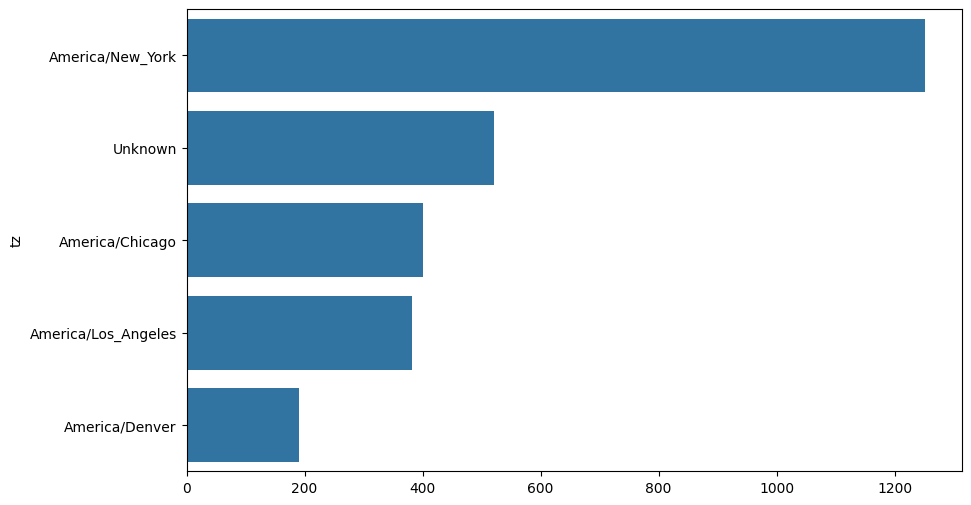

In [ ]:
import seaborn as sns
subset = tz_counts.head()
sns.barplot(y=subset.index, x=subset.to_numpy())

Trường a chứa thông tin về trình duyệt, thiết bị hoặc ứng dụng được sử dụng để thực hiện việc rút gọn URL:

In [ ]:
frame["a"][1]
frame["a"][50]
frame["a"][51][:50]  # long line

'Mozilla/5.0 (Linux; U; Android 2.2.2; en-us; LG-P9'

- Việc phân tích (parsing) toàn bộ thông tin thú vị trong các chuỗi “agent” (tức là User-Agent strings) có thể trông khá phức tạp — vì mỗi chuỗi chứa nhiều thông tin chi tiết về trình duyệt, hệ điều hành, thiết bị, phiên bản, v.v.

- Một chiến lược khả thi để đơn giản hóa là tách (split) token đầu tiên trong chuỗi, vì phần này thường biểu thị loại trình duyệt hoặc khả năng của trình duyệt (browser capability).
Sau đó, ta có thể tạo một bảng tóm tắt (summary) khác để phân tích hành vi người dùng dựa trên loại trình duyệt.

In [ ]:
results = pd.Series([x.split()[0] for x in frame["a"].dropna()])
results.head(5)
results.value_counts().head(8)

Mozilla/5.0                 2594
Mozilla/4.0                  601
GoogleMaps/RochesterNY       121
Opera/9.80                    34
TEST_INTERNET_AGENT           24
GoogleProducer                21
Mozilla/6.0                    5
BlackBerry8520/5.0.0.681       4
Name: count, dtype: int64

- Bây giờ, giả sử bạn muốn phân tách (decompose) các múi giờ phổ biến nhất (top time zones) theo hai nhóm người dùng:
    - Người dùng Windows, và
    - Người dùng không phải Windows (non-Windows).
- Để đơn giản hóa, ta giả định rằng một người dùng được xem là đang dùng Windows nếu trong chuỗi “agent” (user agent string) có chứa từ “Windows”.

- Vì một số bản ghi không có thông tin “agent”, nên ta sẽ loại bỏ (exclude) các bản ghi này khỏi dữ liệu trước khi phân tích.

In [ ]:
cframe = frame[frame["a"].notna()].copy()

- Sau đó, chúng ta muốn tính toán giá trị để xác định xem mỗi hàng có phải là Windows hay không:

In [ ]:
cframe["os"] = np.where(cframe["a"].str.contains("Windows"),
                        "Windows", "Not Windows")
cframe["os"].head(5)

0        Windows
1    Not Windows
2        Windows
3    Not Windows
4        Windows
Name: os, dtype: object

- Sau đó, bạn có thể nhóm dữ liệu theo cột múi giờ và danh sách hệ điều hành mới này:

In [ ]:
by_tz_os = cframe.groupby(["tz", "os"])

- Số lượng nhóm, tương tự như hàm value_counts, có thể được tính bằng
size. Kết quả này sau đó được định dạng lại thành một bảng với unstack:

In [ ]:
agg_counts = by_tz_os.size().unstack().fillna(0)
agg_counts.head()

os,Not Windows,Windows
tz,,
,245.0,276.0
Africa/Cairo,0.0,3.0
Africa/Casablanca,0.0,1.0
Africa/Ceuta,0.0,2.0
Africa/Johannesburg,0.0,1.0


- Cuối cùng, chúng ta sẽ chọn ra các múi giờ (time zones) có tổng số người dùng cao nhất trong toàn bộ dữ liệu.

- Để làm điều này, ta sẽ tạo một mảng chỉ số gián tiếp (indirect index array) dựa trên số lượng bản ghi (row counts) trong bảng tổng hợp agg_counts.
- Sau khi tính tổng số bản ghi của từng múi giờ bằng cách gọi agg_counts.sum("columns"), ta có thể sử dụng phương thức argsort() để lấy ra một mảng chỉ số sắp xếp các giá trị theo thứ tự tăng dần.

In [ ]:
indexer = agg_counts.sum("columns").argsort()
indexer.values[:10]

array([ 2,  7,  5,  4, 14, 11,  9,  8, 24, 26])

- Sử dụng lệnh take để chọn các hàng theo thứ tự đó, sau đó cắt bỏ 10 hàng cuối cùng (giá trị lớn nhất):

In [ ]:
count_subset = agg_counts.take(indexer[-10:])
count_subset

os,Not Windows,Windows
tz,,
America/Sao_Paulo,13.0,20.0
Europe/Madrid,16.0,19.0
Pacific/Honolulu,0.0,36.0
Asia/Tokyo,2.0,35.0
Europe/London,43.0,31.0
America/Denver,132.0,59.0
America/Los_Angeles,130.0,252.0
America/Chicago,115.0,285.0
,245.0,276.0


In [ ]:
agg_counts.sum(axis="columns").nlargest(10)

tz
America/New_York       1251.0
                        521.0
America/Chicago         400.0
America/Los_Angeles     382.0
America/Denver          191.0
Europe/London            74.0
Asia/Tokyo               37.0
Pacific/Honolulu         36.0
Europe/Madrid            35.0
America/Sao_Paulo        33.0
dtype: float64

In [ ]:
plt.figure()

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

- Sau đó, chúng ta có thể trực quan hóa kết quả bằng biểu đồ cột nhóm (grouped bar plot) để so sánh số lượng người dùng Windows và Non-Windows trong từng múi giờ.
- Để thực hiện việc này, ta sẽ sử dụng hàm barplot() của thư viện seaborn (tham khảo Hình 13-2 trong sách).
Trước khi vẽ, ta cần chuẩn bị lại cấu trúc dữ liệu sao cho phù hợp với định dạng đầu vào của seaborn.

- Cụ thể, ta sẽ gọi:
    - count_subset.stack() để chuyển các cột hệ điều hành (Windows / Non-Windows) thành dạng hàng (rows),
rồi dùng reset_index() để đưa các nhãn cột và chỉ số thành các cột dữ liệu thực tế, giúp seaborn dễ dàng nhận biết các trường khi vẽ.

<Axes: xlabel='total', ylabel='tz'>

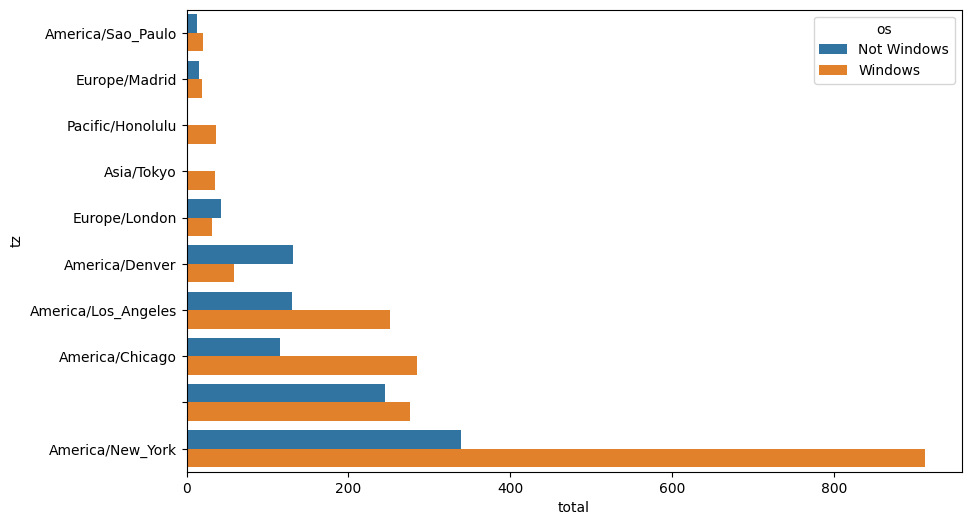

In [ ]:
count_subset = count_subset.stack()
count_subset.name = "total"
count_subset = count_subset.reset_index()
count_subset.head(10)
sns.barplot(x="total", y="tz", hue="os",  data=count_subset)

Việc xem xét tỷ lệ phần trăm tương đối của người dùng Windows trong các nhóm nhỏ hơn khá khó khăn, vì vậy hãy chuẩn hóa tỷ lệ phần trăm của các nhóm thành tổng bằng 1:

In [ ]:
def norm_total(group):
    group["normed_total"] = group["total"] / group["total"].sum()
    return group

results = count_subset.groupby("tz").apply(norm_total)

C:\Users\kn260\AppData\Local\Temp\ipykernel_20132\1595230757.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  results = count_subset.groupby("tz").apply(norm_total)


In [ ]:
plt.figure()

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

<Axes: xlabel='normed_total', ylabel='tz'>

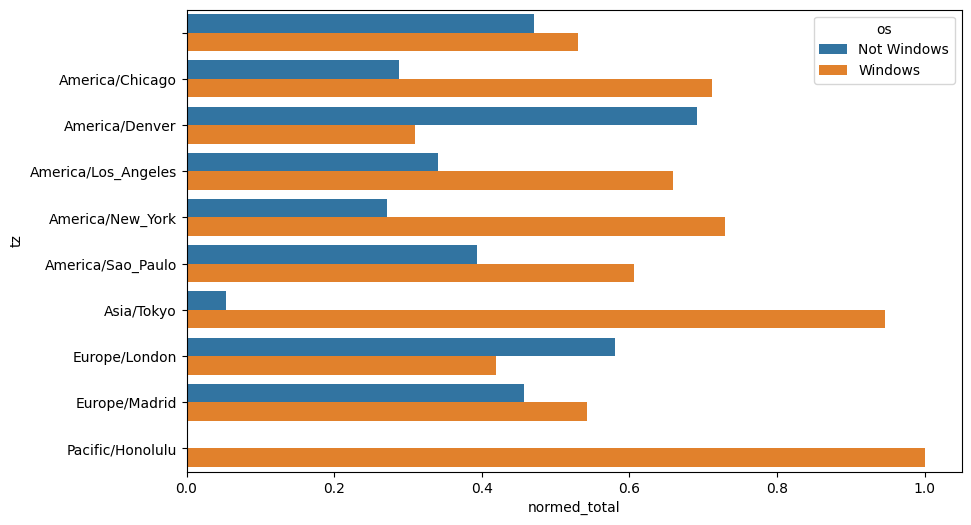

In [ ]:
sns.barplot(x="normed_total", y="tz", hue="os",  data=results)

In [ ]:
g = count_subset.groupby("tz")
results2 = count_subset["total"] / g["total"].transform("sum")

# Kết thúc